<a href="https://colab.research.google.com/github/2026ct05063-lang/2026CT05063-ML_Assignment_2/blob/main/2026CT05063_ML_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#installing UCI Dataset Library
!pip install -q ucimlrepo

In [2]:
#importing the required libraries

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset retrieval
from ucimlrepo import fetch_ucirepo

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


STEP 1 : DOWNLOADING THE DATASET

In [3]:
#Downloading the Dataset

# Fetch Adult Census Income Dataset
adult = fetch_ucirepo(id=2)

# Extract features and target
X_raw = adult.data.features.copy()
y_raw = adult.data.targets.copy()

# Combine into one DataFrame
df = pd.concat([X_raw, y_raw], axis=1)

print("Dataset downloaded successfully!")
print("Initial Dataset Shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Initial Dataset Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


STEP 2: DATA CLEANING AND VALIDATION

In [4]:
#Data Cleaning and Validation
#Standardizing column names and clean text values

# Standardize column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from text columns
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

# Replace '?' with missing values
df = df.replace('?', np.nan)

print("Column names standardized.")
print("Text values cleaned.")
print("Missing value markers replaced.")

Column names standardized.
Text values cleaned.
Missing value markers replaced.


In [5]:
#Normalizing the target variables
# Normalize income labels
df['income'] = (
    df['income']
    .astype(str)
    .str.strip()
    .str.rstrip('.')
)

# Display target categories
print("Income Categories:")
print(df['income'].unique())

print("\nIncome Distribution:")
print(df['income'].value_counts())

Income Categories:
['<=50K' '>50K']

Income Distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [6]:
#Removing Duplicate records

# Checking duplicates before removal
print("Duplicates Before Removal:", df.duplicated().sum())

# Removing duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Verifying final dataset
print("\nDuplicates After Removal:", df.duplicated().sum())

print("Final Dataset Shape:", df.shape)

print("\nFinal Income Distribution:")
print(df['income'].value_counts())

Duplicates Before Removal: 52

Duplicates After Removal: 0
Final Dataset Shape: (48790, 15)

Final Income Distribution:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64


In [7]:
#Final Dataset validation

print("FINAL DATASET VALIDATION")
print("-" * 40)

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Input Features:", len(df.columns) - 1)
print("Target Variable:", 'income')

print("Unique Target Classes:", df['income'].nunique())
print("Remaining Duplicates:", df.duplicated().sum())

print("\nDataset Information:")
df.info()

FINAL DATASET VALIDATION
----------------------------------------
Total Records: 48790
Total Columns: 15
Input Features: 14
Target Variable: income
Unique Target Classes: 2
Remaining Duplicates: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48790 entries, 0 to 48789
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48790 non-null  int64 
 1   workclass       45995 non-null  object
 2   fnlwgt          48790 non-null  int64 
 3   education       48790 non-null  object
 4   education-num   48790 non-null  int64 
 5   marital-status  48790 non-null  object
 6   occupation      45985 non-null  object
 7   relationship    48790 non-null  object
 8   race            48790 non-null  object
 9   sex             48790 non-null  object
 10  capital-gain    48790 non-null  int64 
 11  capital-loss    48790 non-null  int64 
 12  hours-per-week  48790 non-null  int64 
 13  native-

STEP 3: Exploratory Data Analysis (EDA)

In [8]:
#Missing value analysis

# Calculate missing values
missing_count = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

# Create summary
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

missing_summary = missing_summary.sort_values(
    by='Missing Count',
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
occupation,2805,5.749129
workclass,2795,5.728633
native-country,856,1.754458
fnlwgt,0,0.000000
education,0,0.000000
education-num,0,0.000000
age,0,0.000000
marital-status,0,0.000000
relationship,0,0.000000
sex,0,0.000000


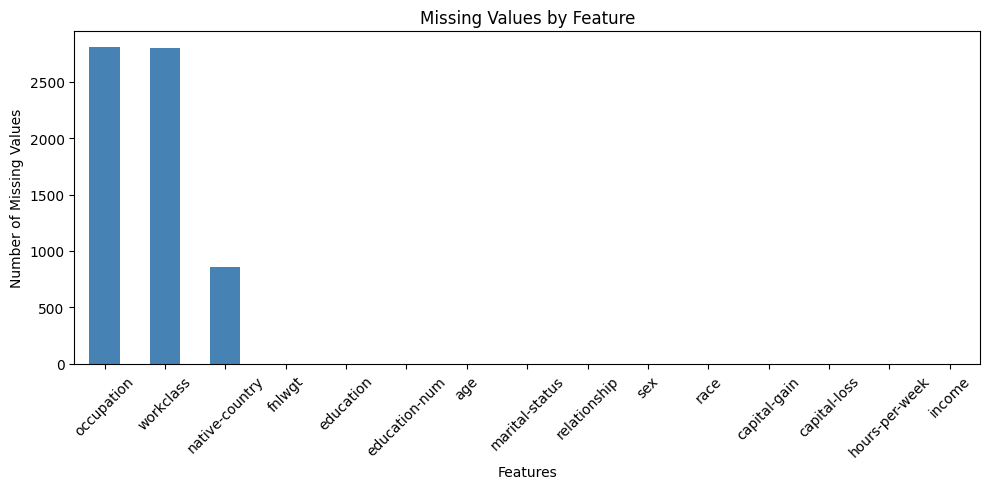

In [9]:
#Visualizing the missing values
plt.figure(figsize=(10, 5))

missing_summary['Missing Count'].plot(
    kind='bar',
    color='steelblue'
)

plt.title('Missing Values by Feature')
plt.xlabel('Features')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
#income distribution analysis; Class Distribution
print("Income Class Distribution:")
print(df['income'].value_counts())

print("\nIncome Class Percentage:")
print(
    df['income'].value_counts(normalize=True) * 100
)

Income Class Distribution:
income
<=50K    37109
>50K     11681
Name: count, dtype: int64

Income Class Percentage:
income
<=50K    76.058619
>50K     23.941381
Name: proportion, dtype: float64


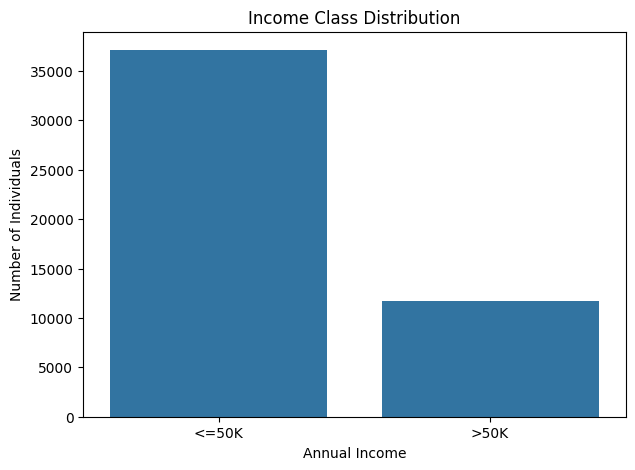

In [11]:
#Income distribution chart
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='income'
)

plt.title('Income Class Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Number of Individuals')
plt.show()

In [12]:
#Identifying numerical and categorical features; Feature classification

# Separate independent variables
X = df.drop(columns=['income'])

# Identify numerical features
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumerical Feature Count:",
      len(numerical_features))

print("Categorical Feature Count:",
      len(categorical_features))

Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Numerical Feature Count: 6
Categorical Feature Count: 8


In [13]:
#Numerical feature analysis; statistical summary

display(df[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,48790.0,38.652798,13.708493,17.0,28.0,37.0,48.00,90.0
fnlwgt,48790.0,189668.999365,105617.231232,12285.0,117555.0,178138.5,237606.25,1490400.0
education-num,48790.0,10.078807,2.570046,1.0,9.0,10.0,12.00,16.0
capital-gain,48790.0,1080.217688,7455.905921,0.0,0.0,0.0,0.00,99999.0
capital-loss,48790.0,87.595573,403.209129,0.0,0.0,0.0,0.00,4356.0
hours-per-week,48790.0,40.425886,12.392729,1.0,40.0,40.0,45.00,99.0


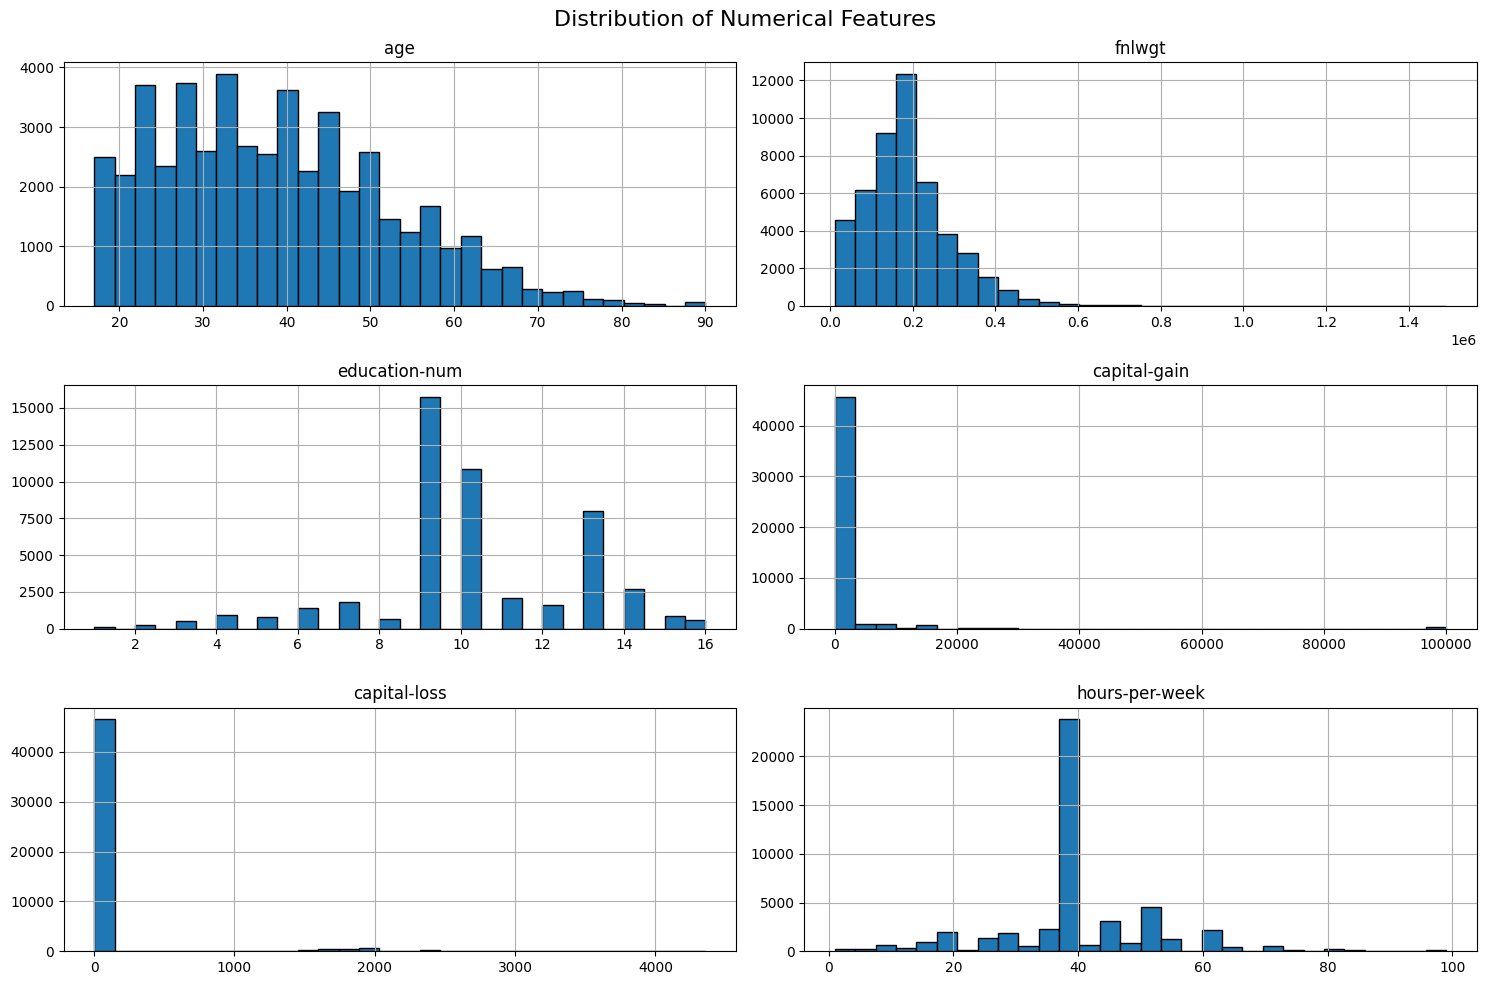

In [14]:
#Numerical feature distributions
df[numerical_features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [15]:
#Categorical feature analysis; Unique category count

for col in categorical_features:
    print("\nFeature:", col)
    print("Unique Categories:", df[col].nunique())
    print(df[col].value_counts().head(10))


Feature: workclass
Unique Categories: 8
workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

Feature: education
Unique Categories: 16
education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
Name: count, dtype: int64

Feature: marital-status
Unique Categories: 7
marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

Feature: occupation
Unique Categories: 14
occupation
Prof-specialty       6165
Craft-repair         6102
Exec-ma

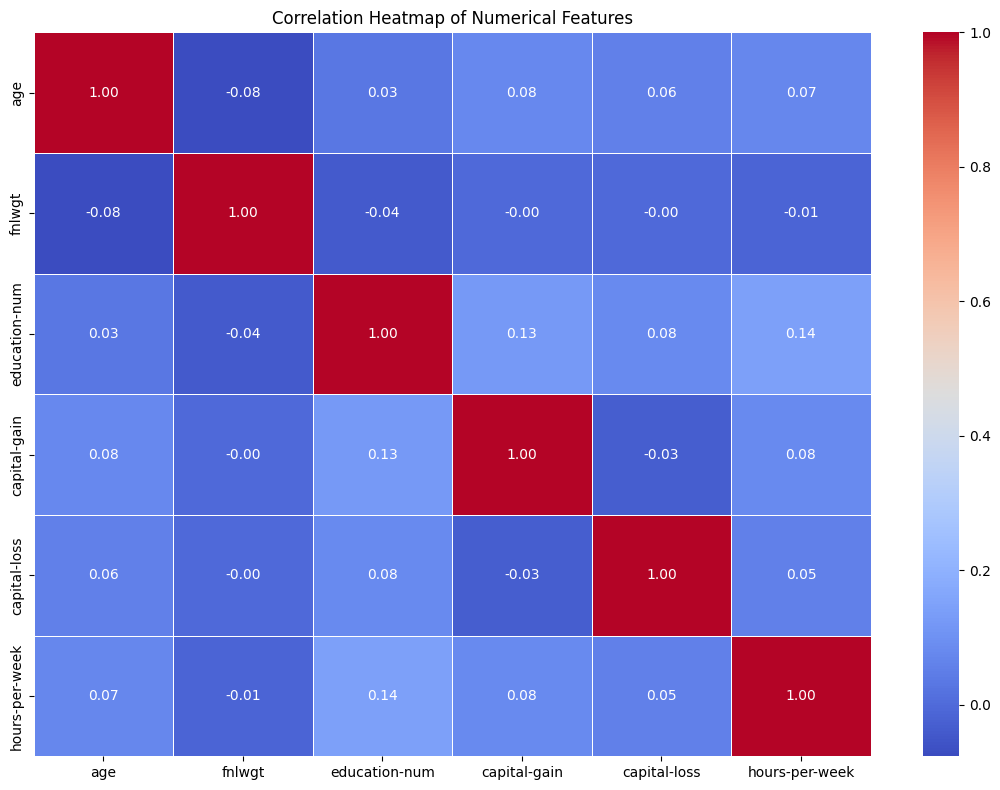

In [16]:
#correlation analysis
plt.figure(figsize=(11, 8))

correlation_matrix = df[
    numerical_features
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [17]:
#Categorical feature distribution
# Analyze categorical features

for col in categorical_features:

    print("\nFeature:", col)

    print("Unique Categories:", df[col].nunique())

    print("\nTop 10 Categories:")
    print(df[col].value_counts().head(10))


Feature: workclass
Unique Categories: 8

Top 10 Categories:
workclass
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

Feature: education
Unique Categories: 16

Top 10 Categories:
education
HS-grad         15770
Some-college    10863
Bachelors        8013
Masters          2656
Assoc-voc        2060
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           954
Prof-school       834
Name: count, dtype: int64

Feature: marital-status
Unique Categories: 7

Top 10 Categories:
marital-status
Married-civ-spouse       22366
Never-married            16082
Divorced                  6630
Separated                 1530
Widowed                   1518
Married-spouse-absent      627
Married-AF-spouse           37
Name: count, dtype: int64

Feature: occupation
Unique Categories: 14

Top 10 Ca

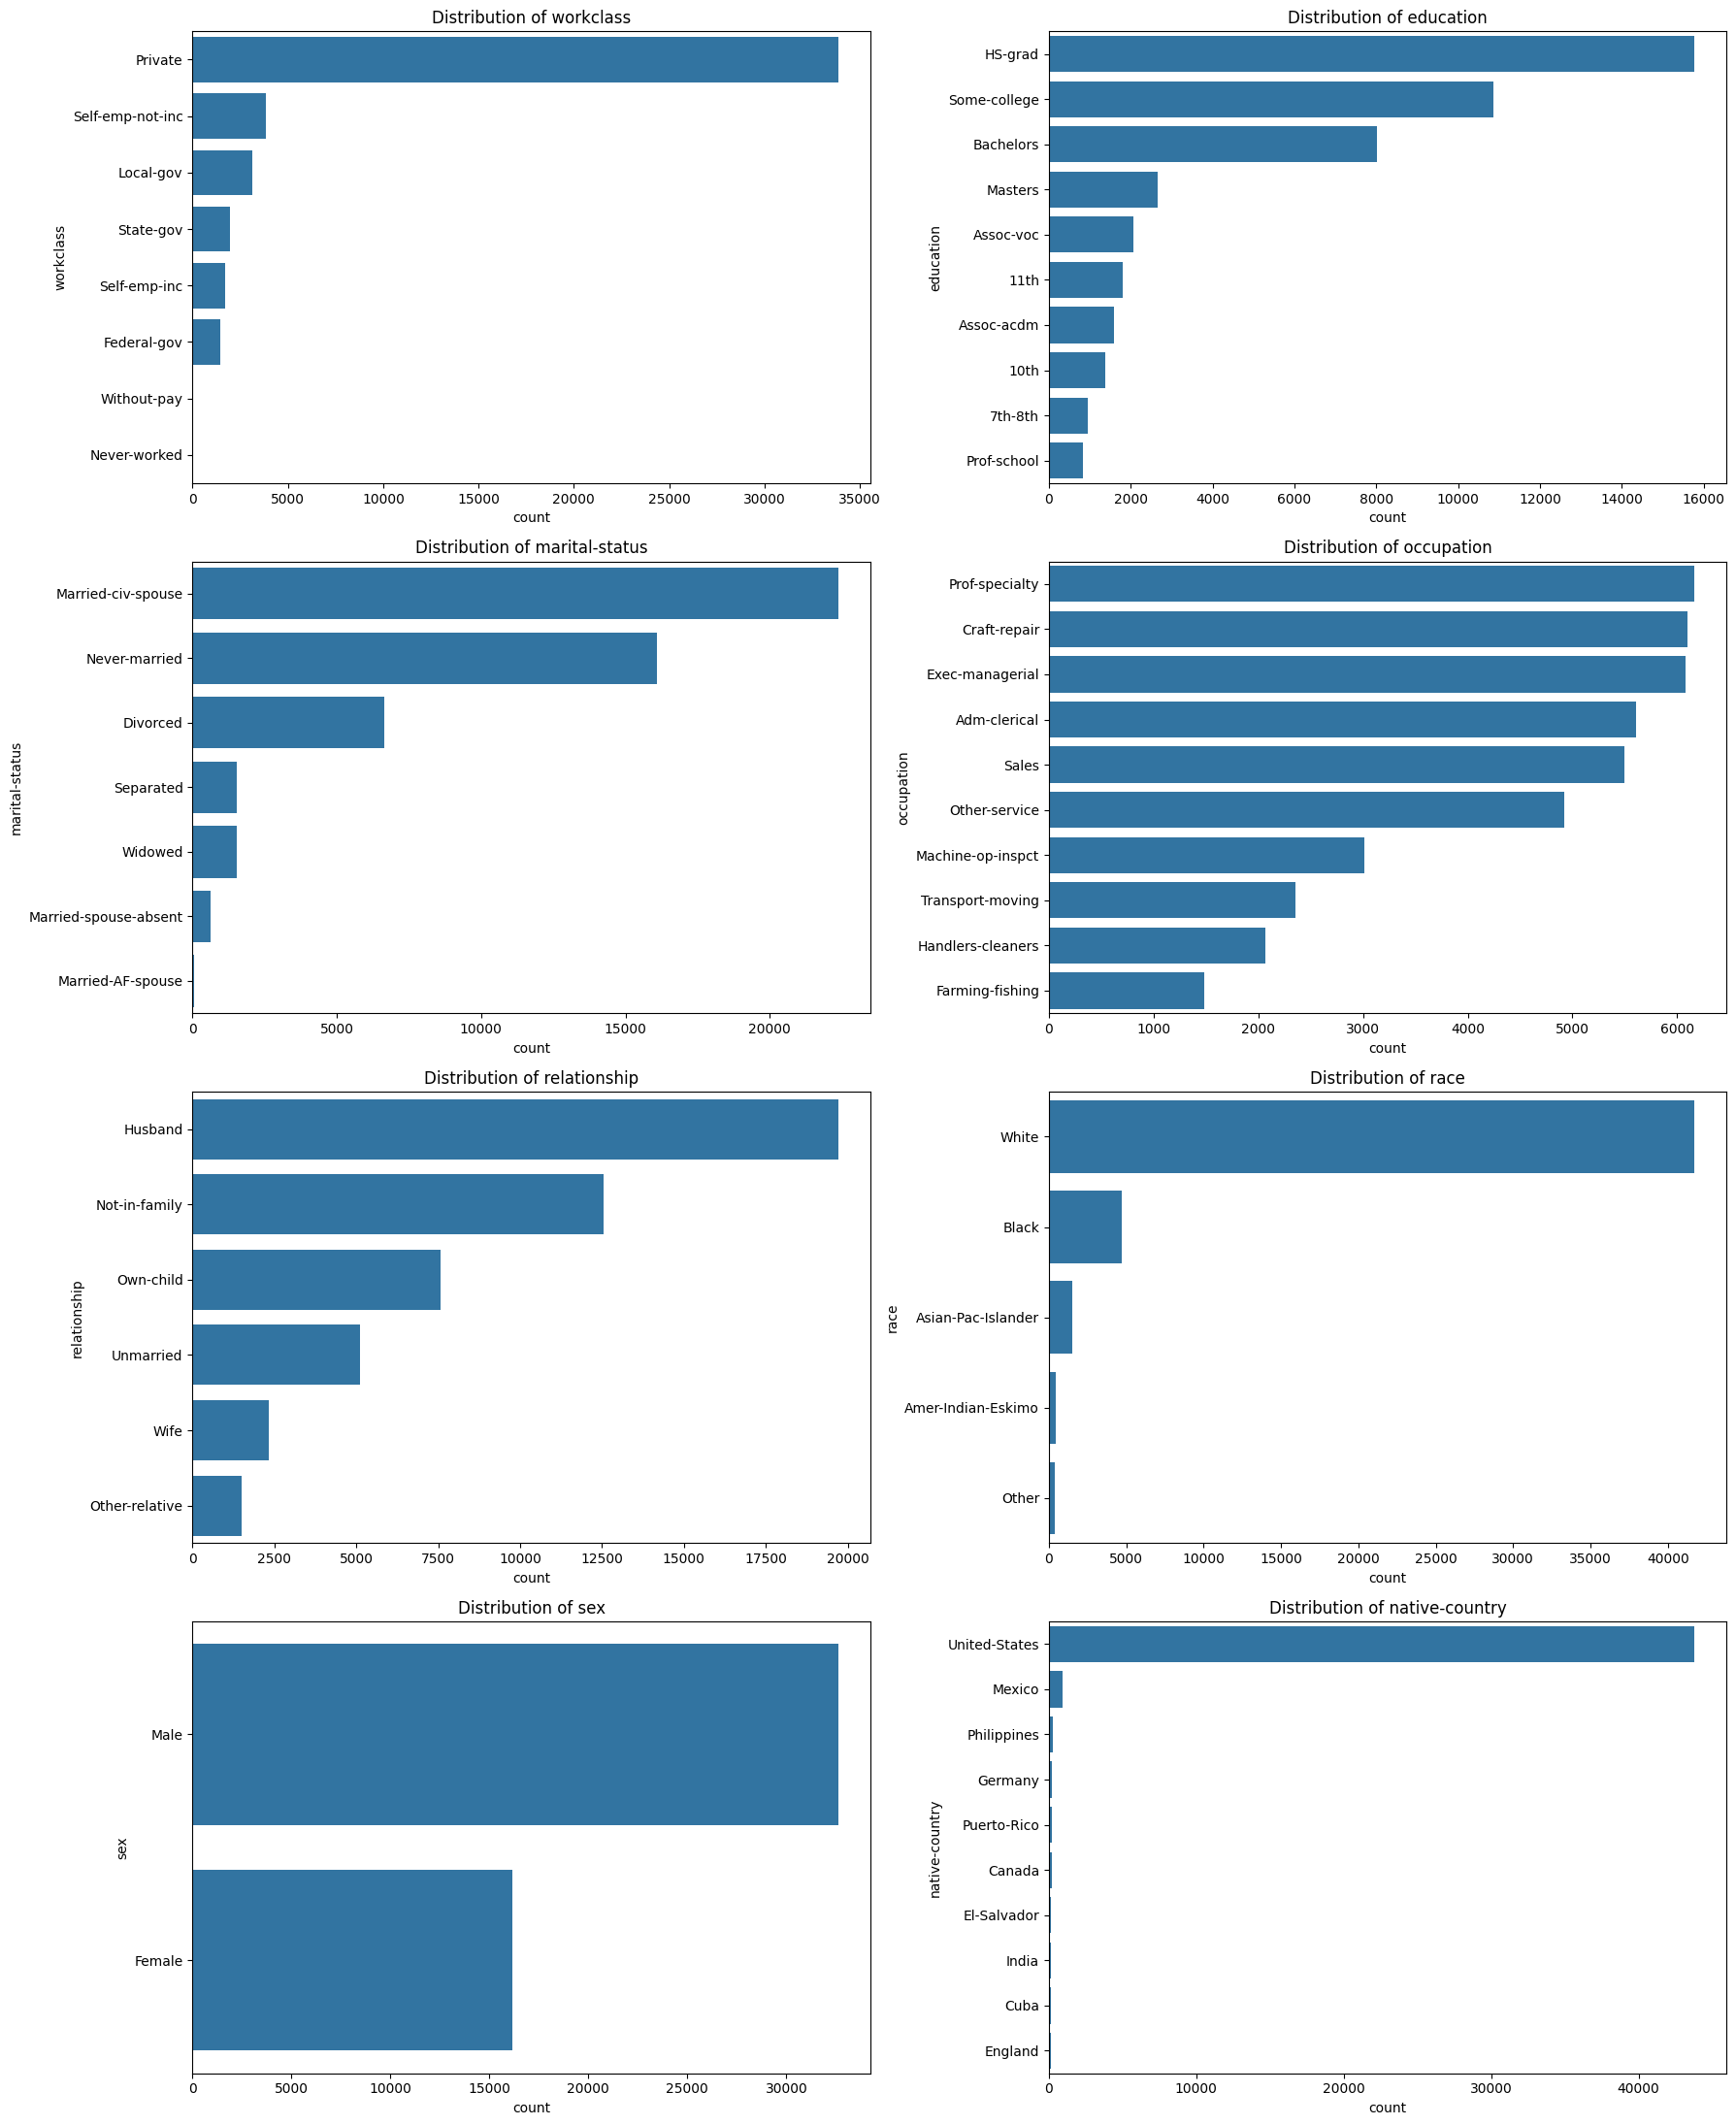

In [19]:
#Visualize categorical features

fig, axes = plt.subplots(
    4, 2,
    figsize=(18, 22)
)

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    order = df[col].value_counts().head(10).index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

STEP 4: DATA PREPROCESSING

In [20]:
#preparing the dataset for machine-learning algorithms
#Defining independent and dependent variables

# Independent variables
X = df.drop(columns=['income'])

# Dependent variable
y = df['income'].map({
    '<=50K': 0,
    '>50K': 1
})

print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

print("\nTarget Class Distribution:")
print(y.value_counts())

print("\nTarget Mapping:")
print("0 = Income <=50K")
print("1 = Income >50K")


Independent Variables Shape: (48790, 14)
Dependent Variable Shape: (48790,)

Target Class Distribution:
income
0    37109
1    11681
Name: count, dtype: int64

Target Mapping:
0 = Income <=50K
1 = Income >50K


In [21]:
#Identifying numerical and categorical features

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:", numerical_features)
print("Number of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("Number of Categorical Features:", len(categorical_features))

Numerical Features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Number of Numerical Features: 6

Categorical Features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Number of Categorical Features: 8


In [22]:
#Train-test Split

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (39032, 14)
Testing Features: (9758, 14)

Training Target: (39032,)
Testing Target: (9758,)

Training Class Distribution:
income
0    76.058106
1    23.941894
Name: proportion, dtype: float64

Testing Class Distribution:
income
0    76.060668
1    23.939332
Name: proportion, dtype: float64


In [23]:
#Numerical Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [24]:
#Categorical preprocessing
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [25]:
#Combining preprocessing transformations
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessing pipeline created successfully!")

Combined preprocessing pipeline created successfully!


In [26]:
#Fit and transform the datasets
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training Data Shape: (39032, 105)
Testing Data Shape: (9758, 105)


STEP 5: LOGISTIC REGRESSION

In [27]:
#importing logistic regression
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Logistic Regression libraries imported successfully!")

Logistic Regression libraries imported successfully!


In [28]:
#initializing the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print(logistic_model)

LogisticRegression(max_iter=1000, random_state=42)


In [29]:
#training the model
logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [30]:
#making prediction
# Predict income classes
y_pred_lr = logistic_model.predict(
    X_test_processed
)

# Predict probabilities
y_prob_lr = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_lr[:10])

Predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 0 0 0 0]


In [31]:
#Evaluating model and perfromance
# Calculate confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

TN, FP, FN, TP = cm_lr.ravel()

# Calculate evaluation metrics
accuracy_lr = accuracy_score(y_test, y_pred_lr)

precision_lr = precision_score(
    y_test, y_pred_lr, zero_division=0
)

recall_lr = recall_score(
    y_test, y_pred_lr, zero_division=0
)

specificity_lr = TN / (TN + FP)

f1_lr = f1_score(
    y_test, y_pred_lr, zero_division=0
)

roc_auc_lr = roc_auc_score(
    y_test, y_prob_lr
)

print("LOGISTIC REGRESSION - PERFORMANCE")
print("-" * 45)

print(f"Accuracy    : {accuracy_lr:.4f}")
print(f"Precision   : {precision_lr:.4f}")
print(f"Recall      : {recall_lr:.4f}")
print(f"Specificity : {specificity_lr:.4f}")
print(f"F1 Score    : {f1_lr:.4f}")
print(f"ROC-AUC     : {roc_auc_lr:.4f}")

LOGISTIC REGRESSION - PERFORMANCE
---------------------------------------------
Accuracy    : 0.8520
Precision   : 0.7304
Recall      : 0.6053
Specificity : 0.9297
F1 Score    : 0.6620
ROC-AUC     : 0.9081


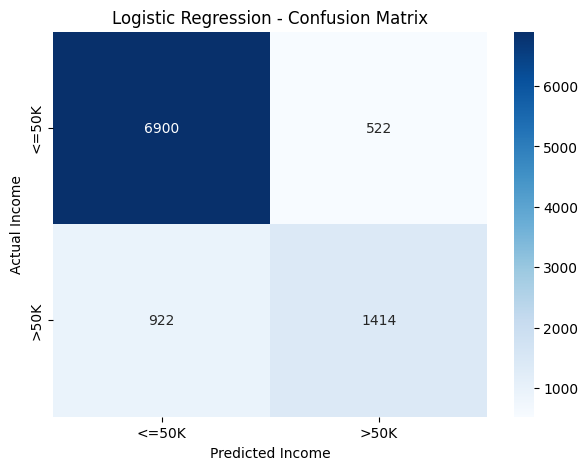

In [32]:
#confusion matrix visualization
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('Logistic Regression - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')

plt.show()

In [33]:
#Logistic Regression Classification Report
print("Logistic Regression Classification Report")

print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=['<=50K', '>50K']
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7422
        >50K       0.73      0.61      0.66      2336

    accuracy                           0.85      9758
   macro avg       0.81      0.77      0.78      9758
weighted avg       0.85      0.85      0.85      9758



In [34]:
#Storing logistic regression results
results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'Specificity': specificity_lr,
    'F1 Score': f1_lr,
    'ROC-AUC': roc_auc_lr
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.852,0.7304,0.6053,0.9297,0.662,0.9081


STEP 6: Decision Tree Classifier

In [35]:
#Iporting decision tree
from sklearn.tree import DecisionTreeClassifier

print("Decision Tree library imported successfully!")

Decision Tree library imported successfully!


In [36]:
#model initialization
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

print(decision_tree_model)

DecisionTreeClassifier(random_state=42)


In [37]:
#training the model
decision_tree_model.fit(
    X_train_processed,
    y_train
)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
#predicting
# Predict income classes
y_pred_dt = decision_tree_model.predict(
    X_test_processed
)

# Predict probabilities
y_prob_dt = decision_tree_model.predict_proba(
    X_test_processed
)[:, 1]

print("Decision Tree predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_dt[:10])

Decision Tree predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 0 0 0 0]


In [39]:
#evaluating model performance
# Calculate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

TN, FP, FN, TP = cm_dt.ravel()

# Calculate metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test, y_pred_dt, zero_division=0
)

recall_dt = recall_score(
    y_test, y_pred_dt, zero_division=0
)

specificity_dt = TN / (TN + FP)

f1_dt = f1_score(
    y_test, y_pred_dt, zero_division=0
)

roc_auc_dt = roc_auc_score(
    y_test, y_prob_dt
)

print("DECISION TREE - PERFORMANCE")
print("-" * 45)

print(f"Accuracy    : {accuracy_dt:.4f}")
print(f"Precision   : {precision_dt:.4f}")
print(f"Recall      : {recall_dt:.4f}")
print(f"Specificity : {specificity_dt:.4f}")
print(f"F1 Score    : {f1_dt:.4f}")
print(f"ROC-AUC     : {roc_auc_dt:.4f}")

DECISION TREE - PERFORMANCE
---------------------------------------------
Accuracy    : 0.8214
Precision   : 0.6242
Recall      : 0.6378
Specificity : 0.8791
F1 Score    : 0.6310
ROC-AUC     : 0.7587


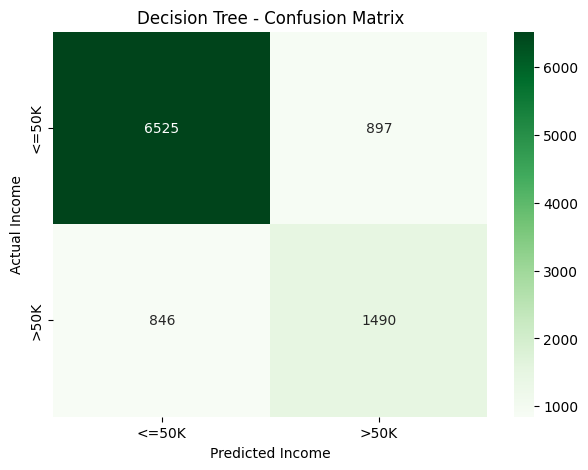

In [40]:
#confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')

plt.show()

In [41]:
#Decision Tree Classification Report
print("Decision Tree Classification Report")

print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=['<=50K', '>50K']
    )
)

Decision Tree Classification Report
              precision    recall  f1-score   support

       <=50K       0.89      0.88      0.88      7422
        >50K       0.62      0.64      0.63      2336

    accuracy                           0.82      9758
   macro avg       0.75      0.76      0.76      9758
weighted avg       0.82      0.82      0.82      9758



In [44]:
#updating the model results

results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'Specificity': specificity_lr,
    'F1 Score': f1_lr,
    'ROC-AUC': roc_auc_lr
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_dt,
    'Precision': precision_dt,
    'Recall': recall_dt,
    'Specificity': specificity_dt,
    'F1 Score': f1_dt,
    'ROC-AUC': roc_auc_dt
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.8520,0.7304,0.6053,0.9297,0.662,0.9081
1,Decision Tree,0.8214,0.6242,0.6378,0.8791,0.631,0.7587


STEP 7: K-Nearest Neighbors

In [45]:
#Importing KNN
from sklearn.neighbors import KNeighborsClassifier

print("KNN library imported successfully!")

KNN library imported successfully!


In [46]:
#Model initialization
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean',
    weights='uniform',
    n_jobs=-1
)

print(knn_model)

KNeighborsClassifier(metric='euclidean', n_jobs=-1)


In [47]:
#training the model
knn_model.fit(
    X_train_processed,
    y_train
)

print("KNN model trained successfully!")

KNN model trained successfully!


In [48]:
#predicting
y_pred_knn = knn_model.predict(
    X_test_processed
)

y_prob_knn = knn_model.predict_proba(
    X_test_processed
)[:, 1]

print("KNN predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_knn[:10])

KNN predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 0 0 0 0]


In [49]:
#evaluating the model
cm_knn = confusion_matrix(y_test, y_pred_knn)

TN, FP, FN, TP = cm_knn.ravel()

accuracy_knn = accuracy_score(y_test, y_pred_knn)

precision_knn = precision_score(
    y_test, y_pred_knn, zero_division=0
)

recall_knn = recall_score(
    y_test, y_pred_knn, zero_division=0
)

specificity_knn = TN / (TN + FP)

f1_knn = f1_score(
    y_test, y_pred_knn, zero_division=0
)

roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("KNN - PERFORMANCE")
print("-" * 45)

print(f"Accuracy    : {accuracy_knn:.4f}")
print(f"Precision   : {precision_knn:.4f}")
print(f"Recall      : {recall_knn:.4f}")
print(f"Specificity : {specificity_knn:.4f}")
print(f"F1 Score    : {f1_knn:.4f}")
print(f"ROC-AUC     : {roc_auc_knn:.4f}")

KNN - PERFORMANCE
---------------------------------------------
Accuracy    : 0.8389
Precision   : 0.6835
Recall      : 0.6092
Specificity : 0.9112
F1 Score    : 0.6442
ROC-AUC     : 0.8667


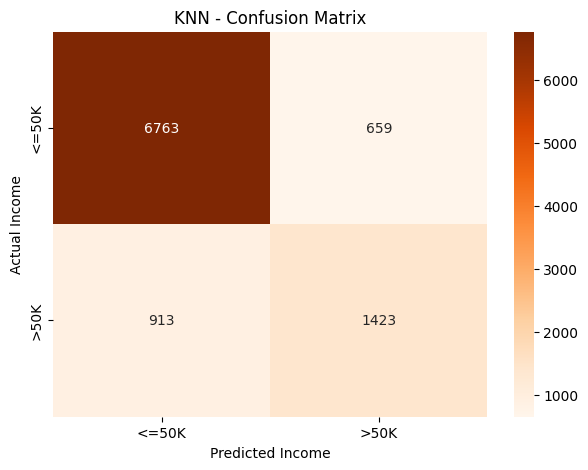

In [50]:
#confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('KNN - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')

plt.show()

In [51]:
#KNN Classification Report
print("KNN Classification Report")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=['<=50K', '>50K']
    )
)

KNN Classification Report
              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      7422
        >50K       0.68      0.61      0.64      2336

    accuracy                           0.84      9758
   macro avg       0.78      0.76      0.77      9758
weighted avg       0.83      0.84      0.84      9758



In [52]:
#updating model comparison
results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'Specificity': specificity_lr,
    'F1 Score': f1_lr,
    'ROC-AUC': roc_auc_lr
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_dt,
    'Precision': precision_dt,
    'Recall': recall_dt,
    'Specificity': specificity_dt,
    'F1 Score': f1_dt,
    'ROC-AUC': roc_auc_dt
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'KNN',
    'Accuracy': accuracy_knn,
    'Precision': precision_knn,
    'Recall': recall_knn,
    'Specificity': specificity_knn,
    'F1 Score': f1_knn,
    'ROC-AUC': roc_auc_knn
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.8520,0.7304,0.6053,0.9297,0.6620,0.9081
1,Decision Tree,0.8214,0.6242,0.6378,0.8791,0.6310,0.7587
2,KNN,0.8389,0.6835,0.6092,0.9112,0.6442,0.8667


STEP 8: NAIVE BAYES CLASSIFIER

In [53]:
#importing gaussian naive bayes
from sklearn.naive_bayes import GaussianNB

print("Gaussian Naive Bayes imported successfully!")

Gaussian Naive Bayes imported successfully!


In [54]:
#preparing data for naive bayes
from scipy.sparse import issparse

if issparse(X_train_processed):
    X_train_nb = X_train_processed.toarray()
else:
    X_train_nb = X_train_processed

if issparse(X_test_processed):
    X_test_nb = X_test_processed.toarray()
else:
    X_test_nb = X_test_processed

print("Naive Bayes data preparation completed!")

print("Training Shape:", X_train_nb.shape)
print("Testing Shape:", X_test_nb.shape)

Naive Bayes data preparation completed!
Training Shape: (39032, 105)
Testing Shape: (9758, 105)


In [55]:
#initializing the model
naive_bayes_model = GaussianNB()

print(naive_bayes_model)

GaussianNB()


In [56]:
#training the model
naive_bayes_model.fit(
    X_train_nb,
    y_train
)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [57]:
#predicting
y_pred_nb = naive_bayes_model.predict(
    X_test_nb
)

y_prob_nb = naive_bayes_model.predict_proba(
    X_test_nb
)[:, 1]

print("Naive Bayes predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_nb[:10])

Naive Bayes predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[1 0 0 0 1 1 0 1 0 0]


In [58]:
#evaluating
cm_nb = confusion_matrix(y_test, y_pred_nb)

TN, FP, FN, TP = cm_nb.ravel()

accuracy_nb = accuracy_score(y_test, y_pred_nb)

precision_nb = precision_score(
    y_test, y_pred_nb, zero_division=0
)

recall_nb = recall_score(
    y_test, y_pred_nb, zero_division=0
)

specificity_nb = TN / (TN + FP)

f1_nb = f1_score(
    y_test, y_pred_nb, zero_division=0
)

roc_auc_nb = roc_auc_score(y_test, y_prob_nb)

print("NAIVE BAYES - PERFORMANCE")
print("-" * 45)

print(f"Accuracy    : {accuracy_nb:.4f}")
print(f"Precision   : {precision_nb:.4f}")
print(f"Recall      : {recall_nb:.4f}")
print(f"Specificity : {specificity_nb:.4f}")
print(f"F1 Score    : {f1_nb:.4f}")
print(f"ROC-AUC     : {roc_auc_nb:.4f}")

NAIVE BAYES - PERFORMANCE
---------------------------------------------
Accuracy    : 0.5990
Precision   : 0.3672
Recall      : 0.9336
Specificity : 0.4937
F1 Score    : 0.5271
ROC-AUC     : 0.8174


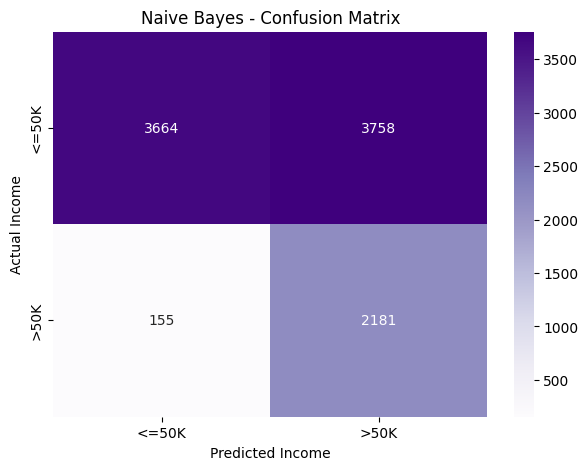

In [59]:
#confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('Naive Bayes - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')

plt.show()

In [60]:
#Naive Bayes Classification Report
print("Naive Bayes Classification Report")

print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=['<=50K', '>50K']
    )
)

Naive Bayes Classification Report
              precision    recall  f1-score   support

       <=50K       0.96      0.49      0.65      7422
        >50K       0.37      0.93      0.53      2336

    accuracy                           0.60      9758
   macro avg       0.66      0.71      0.59      9758
weighted avg       0.82      0.60      0.62      9758



In [61]:
#updating model comparison
results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'Specificity': specificity_lr,
    'F1 Score': f1_lr,
    'ROC-AUC': roc_auc_lr
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_dt,
    'Precision': precision_dt,
    'Recall': recall_dt,
    'Specificity': specificity_dt,
    'F1 Score': f1_dt,
    'ROC-AUC': roc_auc_dt
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'KNN',
    'Accuracy': accuracy_knn,
    'Precision': precision_knn,
    'Recall': recall_knn,
    'Specificity': specificity_knn,
    'F1 Score': f1_knn,
    'ROC-AUC': roc_auc_knn
})

results.append({
    'Model': 'Naive Bayes',
    'Accuracy': accuracy_nb,
    'Precision': precision_nb,
    'Recall': recall_nb,
    'Specificity': specificity_nb,
    'F1 Score': f1_nb,
    'ROC-AUC': roc_auc_nb
})

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
0,Logistic Regression,0.8520,0.7304,0.6053,0.9297,0.6620,0.9081
1,Decision Tree,0.8214,0.6242,0.6378,0.8791,0.6310,0.7587
2,KNN,0.8389,0.6835,0.6092,0.9112,0.6442,0.8667
3,Naive Bayes,0.5990,0.3672,0.9336,0.4937,0.5271,0.8174


STEP 9: RANDOM FOREST CLASSIFIER

In [62]:
#importing random forest
from sklearn.ensemble import RandomForestClassifier

print("Random Forest library imported successfully!")

Random Forest library imported successfully!


In [63]:
#initializing the model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print(random_forest_model)

RandomForestClassifier(n_jobs=-1, random_state=42)


In [64]:
#training the model
random_forest_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [65]:
#predicting
y_pred_rf = random_forest_model.predict(
    X_test_processed
)

y_prob_rf = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest predictions generated successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!

First 10 Actual Values:
[0 0 0 0 1 0 0 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 0 0 0 0]


In [66]:
#evaluating model performance
cm_rf = confusion_matrix(y_test, y_pred_rf)

TN, FP, FN, TP = cm_rf.ravel()

accuracy_rf = accuracy_score(y_test, y_pred_rf)

precision_rf = precision_score(
    y_test, y_pred_rf, zero_division=0
)

recall_rf = recall_score(
    y_test, y_pred_rf, zero_division=0
)

specificity_rf = TN / (TN + FP)

f1_rf = f1_score(
    y_test, y_pred_rf, zero_division=0
)

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("RANDOM FOREST - PERFORMANCE")
print("-" * 45)

print(f"Accuracy    : {accuracy_rf:.4f}")
print(f"Precision   : {precision_rf:.4f}")
print(f"Recall      : {recall_rf:.4f}")
print(f"Specificity : {specificity_rf:.4f}")
print(f"F1 Score    : {f1_rf:.4f}")
print(f"ROC-AUC     : {roc_auc_rf:.4f}")

RANDOM FOREST - PERFORMANCE
---------------------------------------------
Accuracy    : 0.8558
Precision   : 0.7289
Recall      : 0.6331
Specificity : 0.9259
F1 Score    : 0.6777
ROC-AUC     : 0.9050


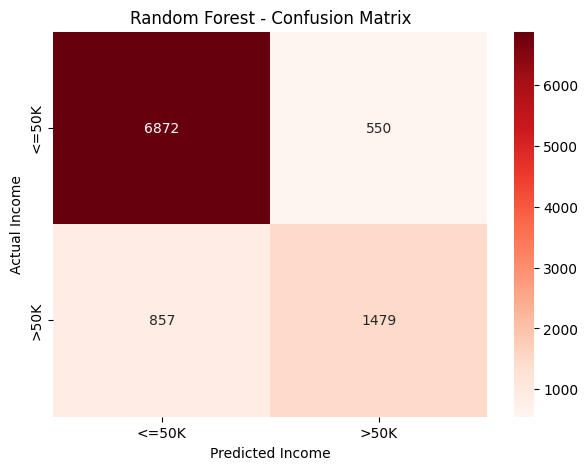

In [67]:
#confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=['<=50K', '>50K'],
    yticklabels=['<=50K', '>50K']
)

plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted Income')
plt.ylabel('Actual Income')

plt.show()

In [68]:
#Random Forest Classification Report
print("Random Forest Classification Report")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=['<=50K', '>50K']
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7422
        >50K       0.73      0.63      0.68      2336

    accuracy                           0.86      9758
   macro avg       0.81      0.78      0.79      9758
weighted avg       0.85      0.86      0.85      9758



In [69]:
#updating model comparison
results = []

results.append({
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_lr,
    'Precision': precision_lr,
    'Recall': recall_lr,
    'Specificity': specificity_lr,
    'F1 Score': f1_lr,
    'ROC-AUC': roc_auc_lr
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'Decision Tree',
    'Accuracy': accuracy_dt,
    'Precision': precision_dt,
    'Recall': recall_dt,
    'Specificity': specificity_dt,
    'F1 Score': f1_dt,
    'ROC-AUC': roc_auc_dt
})

results_df = pd.DataFrame(results)

results.append({
    'Model': 'KNN',
    'Accuracy': accuracy_knn,
    'Precision': precision_knn,
    'Recall': recall_knn,
    'Specificity': specificity_knn,
    'F1 Score': f1_knn,
    'ROC-AUC': roc_auc_knn
})

results.append({
    'Model': 'Naive Bayes',
    'Accuracy': accuracy_nb,
    'Precision': precision_nb,
    'Recall': recall_nb,
    'Specificity': specificity_nb,
    'F1 Score': f1_nb,
    'ROC-AUC': roc_auc_nb
})

results.append({
    'Model': 'Random Forest',
    'Accuracy': accuracy_rf,
    'Precision': precision_rf,
    'Recall': recall_rf,
    'Specificity': specificity_rf,
    'F1 Score': f1_rf,
    'ROC-AUC': roc_auc_rf
})

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
4,Random Forest,0.8558,0.7289,0.6331,0.9259,0.6777,0.9050
0,Logistic Regression,0.8520,0.7304,0.6053,0.9297,0.6620,0.9081
2,KNN,0.8389,0.6835,0.6092,0.9112,0.6442,0.8667
1,Decision Tree,0.8214,0.6242,0.6378,0.8791,0.6310,0.7587
3,Naive Bayes,0.5990,0.3672,0.9336,0.4937,0.5271,0.8174


In [70]:
#random forest-feature importance
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")

display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
1,num__fnlwgt,0.172429
0,num__age,0.153260
3,num__capital-gain,0.096357
5,num__hours-per-week,0.085893
2,num__education-num,0.059917
32,cat__marital-status_Married-civ-spouse,0.059847
51,cat__relationship_Husband,0.049065
4,num__capital-loss,0.030635
34,cat__marital-status_Never-married,0.024609
40,cat__occupation_Exec-managerial,0.016366


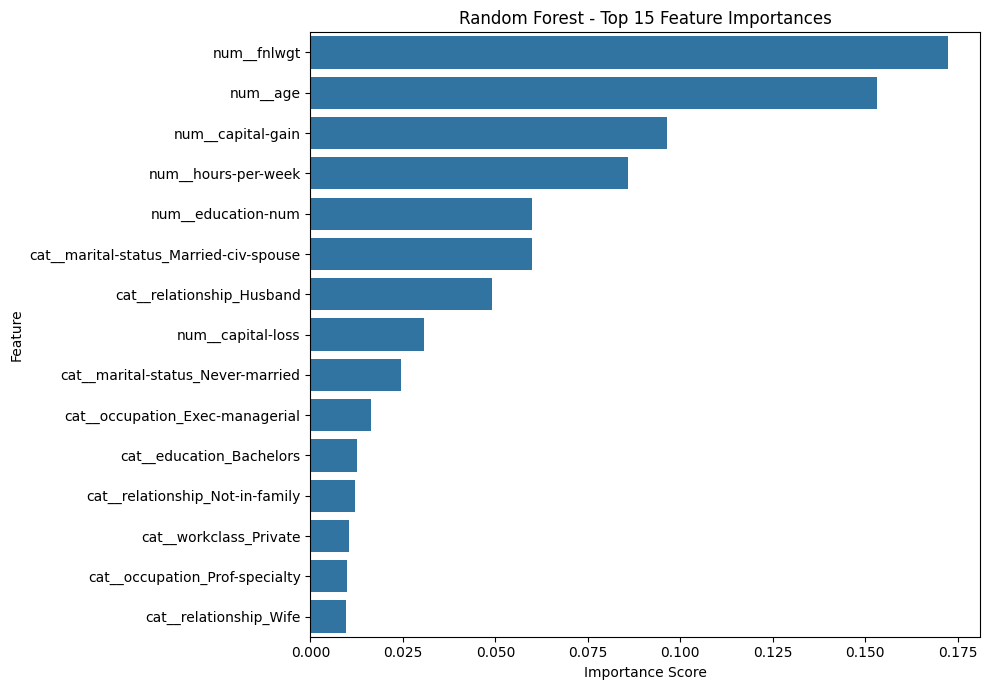

In [71]:
#feature importance visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Top 15 Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

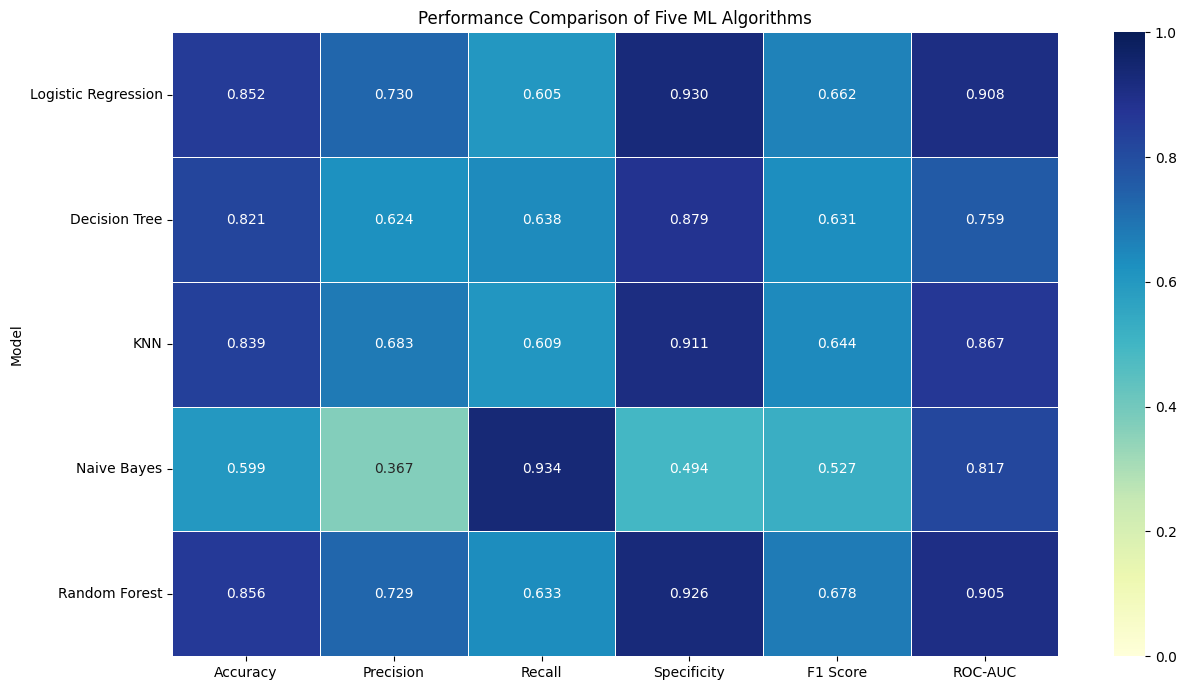

In [72]:
#Comparing all 5 models
comparison_metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'Specificity',
    'F1 Score',
    'ROC-AUC'
]

comparison_plot = results_df.set_index('Model')[comparison_metrics]

plt.figure(figsize=(13, 7))

sns.heatmap(
    comparison_plot,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title('Performance Comparison of Five ML Algorithms')
plt.tight_layout()
plt.show()

In [73]:
#Identifying best performing model
best_accuracy_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

best_f1_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

best_roc_model = results_df.loc[
    results_df['ROC-AUC'].idxmax()
]

print("FINAL MODEL SELECTION")
print("=" * 45)

print(
    "Best Accuracy:",
    best_accuracy_model['Model'],
    round(best_accuracy_model['Accuracy'], 4)
)

print(
    "Best F1 Score:",
    best_f1_model['Model'],
    round(best_f1_model['F1 Score'], 4)
)

print(
    "Best ROC-AUC:",
    best_roc_model['Model'],
    round(best_roc_model['ROC-AUC'], 4)
)

FINAL MODEL SELECTION
Best Accuracy: Random Forest 0.8558
Best F1 Score: Random Forest 0.6777
Best ROC-AUC: Logistic Regression 0.9081


In [74]:
#importing MCC
from sklearn.metrics import matthews_corrcoef

print("MCC metric imported successfully!")

MCC metric imported successfully!


In [75]:
#calculating MCC for each model
mcc_lr = matthews_corrcoef(y_test, y_pred_lr)
mcc_dt = matthews_corrcoef(y_test, y_pred_dt)
mcc_knn = matthews_corrcoef(y_test, y_pred_knn)
mcc_nb = matthews_corrcoef(y_test, y_pred_nb)
mcc_rf = matthews_corrcoef(y_test, y_pred_rf)

print("Logistic Regression MCC:", round(mcc_lr, 4))
print("Decision Tree MCC:", round(mcc_dt, 4))
print("KNN MCC:", round(mcc_knn, 4))
print("Naive Bayes MCC:", round(mcc_nb, 4))
print("Random Forest MCC:", round(mcc_rf, 4))

Logistic Regression MCC: 0.5724
Decision Tree MCC: 0.5132
KNN MCC: 0.542
Naive Bayes MCC: 0.3736
Random Forest MCC: 0.5878


In [76]:
# Calculate Matthews Correlation Coefficient

mcc_lr = matthews_corrcoef(y_test, y_pred_lr)

mcc_dt = matthews_corrcoef(y_test, y_pred_dt)

mcc_knn = matthews_corrcoef(y_test, y_pred_knn)

mcc_nb = matthews_corrcoef(y_test, y_pred_nb)

mcc_rf = matthews_corrcoef(y_test, y_pred_rf)


# Display MCC results

print("MATTHEWS CORRELATION COEFFICIENT")
print("=" * 45)

print(f"Logistic Regression : {mcc_lr:.4f}")
print(f"Decision Tree       : {mcc_dt:.4f}")
print(f"KNN                 : {mcc_knn:.4f}")
print(f"Naive Bayes         : {mcc_nb:.4f}")
print(f"Random Forest       : {mcc_rf:.4f}")

MATTHEWS CORRELATION COEFFICIENT
Logistic Regression : 0.5724
Decision Tree       : 0.5132
KNN                 : 0.5420
Naive Bayes         : 0.3736
Random Forest       : 0.5878


In [77]:
# Adding MCC values to the existing results

mcc_values = {
    'Logistic Regression': mcc_lr,
    'Decision Tree': mcc_dt,
    'KNN': mcc_knn,
    'Naive Bayes': mcc_nb,
    'Random Forest': mcc_rf
}

results_df['MCC'] = results_df['Model'].map(mcc_values)

# Displaying the updated comparison table

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC,MCC
0,Random Forest,0.855811,0.728931,0.633134,0.925896,0.677663,0.904980,0.587799
1,Logistic Regression,0.852019,0.730372,0.605308,0.929669,0.661985,0.908126,0.572427
2,KNN,0.838901,0.683477,0.609161,0.911210,0.644183,0.866729,0.542003
3,Decision Tree,0.821377,0.624214,0.637842,0.879143,0.630955,0.758681,0.513199
4,Naive Bayes,0.598996,0.367234,0.933647,0.493667,0.527130,0.817373,0.373606


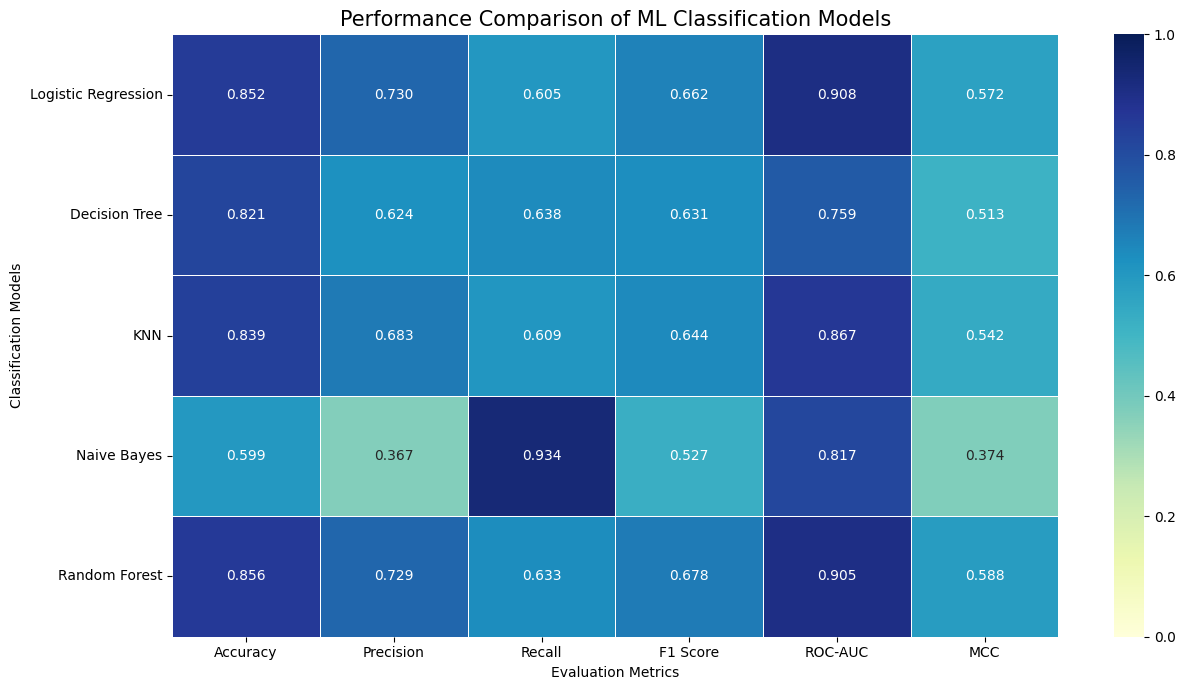

In [78]:
#Graphical comparison of all five ML models

import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score',
    'ROC-AUC',
    'MCC'
]

comparison_data = results_df.set_index('Model')[metrics]

plt.figure(figsize=(13, 7))

sns.heatmap(
    comparison_data,
    annot=True,
    fmt='.3f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title(
    'Performance Comparison of ML Classification Models',
    fontsize=15
)

plt.xlabel('Evaluation Metrics')
plt.ylabel('Classification Models')

plt.tight_layout()
plt.show()

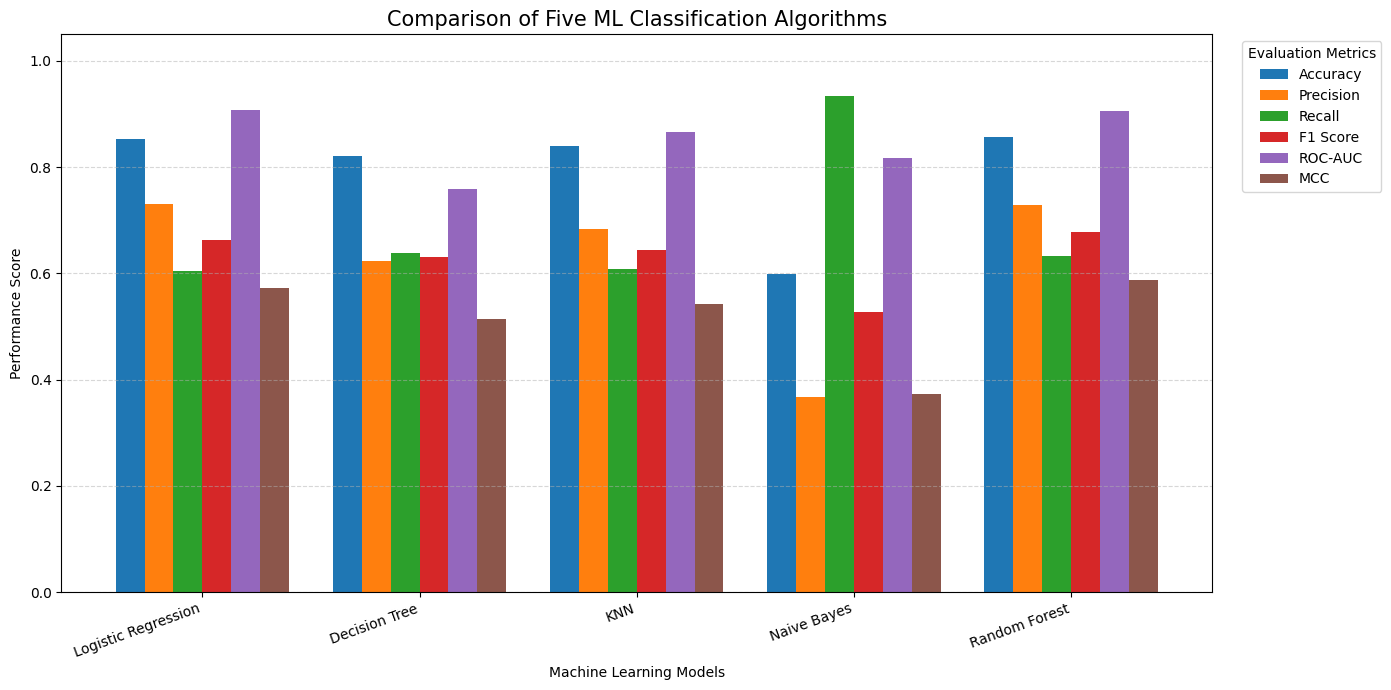

In [79]:
#bar chart comparison

comparison_data.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title(
    'Comparison of Five ML Classification Algorithms',
    fontsize=15
)

plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')

plt.ylim(0, 1.05)

plt.xticks(rotation=20, ha='right')

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [81]:
#Model-wise observations and final selection

model_observations = {
    'Logistic Regression':
        'Achieved 85.20% accuracy and the highest ROC-AUC of 0.9081. '
        'It provides strong classification performance.',

    'Decision Tree':
        'Achieved 82.14% accuracy. Its ROC-AUC of 0.7587 was the '
        'lowest among the five models.',

    'KNN':
        'Achieved 83.89% accuracy and an F1-score of 0.6442, '
        'showing reasonably balanced performance.',

    'Naive Bayes':
        'Achieved the highest recall of 0.9336 but lower accuracy '
        'of 59.90%, indicating many false-positive predictions.',

    'Random Forest':
        'Achieved the highest accuracy of 85.58%, F1-score of '
        '0.6777 and MCC of 0.5878.'
}

for model, observation in model_observations.items():
    print(f'\n{model}')
    print('-' * 60)
    print(observation)


Logistic Regression
------------------------------------------------------------
Achieved 85.20% accuracy and the highest ROC-AUC of 0.9081. It provides strong classification performance.

Decision Tree
------------------------------------------------------------
Achieved 82.14% accuracy. Its ROC-AUC of 0.7587 was the lowest among the five models.

KNN
------------------------------------------------------------
Achieved 83.89% accuracy and an F1-score of 0.6442, showing reasonably balanced performance.

Naive Bayes
------------------------------------------------------------
Achieved the highest recall of 0.9336 but lower accuracy of 59.90%, indicating many false-positive predictions.

Random Forest
------------------------------------------------------------
Achieved the highest accuracy of 85.58%, F1-score of 0.6777 and MCC of 0.5878.
